# PhiUSIIL Phishing URL Dataset: Exploratory Data Analysis

This reproducible notebook analyzes the verified UCI CSV without modifying it. It does not train a model, select features, resample, normalize, or prepare splits. UCI labels remain unchanged: `0 = phishing`, `1 = legitimate`. The eventual deployment detector receives a URL and must not fetch or execute the destination, so feature availability is assessed separately from observed discrimination.

## 1. Imports and reproducibility

Full-data summaries use all rows. Dense plots use an explicitly stratified, fixed-seed sample and do not write sampled data.

In [1]:
from pathlib import Path
import os, tempfile
ROOT = Path.cwd()
if not (ROOT / "data/raw/PhiUSIIL_Phishing_URL_Dataset.csv").exists(): ROOT = ROOT.parent
DATA_PATH = ROOT / "data/raw/PhiUSIIL_Phishing_URL_Dataset.csv"
assert DATA_PATH.is_file(), DATA_PATH
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "phiusiil-matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import mannwhitneyu
from IPython.display import display
SEED = 2026
pd.set_option("display.max_columns", 80); pd.set_option("display.max_rows", 100); pd.set_option("display.max_colwidth", 110)
sns.set_theme(style="whitegrid", context="notebook")
df = pd.read_csv(DATA_PATH)
print("pandas", pd.__version__, "|", DATA_PATH)

pandas 3.1.0 | C:\Users\baiye\intelligent-phishing-ti-ml\data\raw\PhiUSIIL_Phishing_URL_Dataset.csv


## 2. Dataset overview and quality

Read the source CSV directly. No labels, rows, or columns are changed.

In [2]:
print(f"Shape: {df.shape[0]:,} × {df.shape[1]:,}")
print(f"Deep in-memory usage: {df.memory_usage(deep=True).sum():,} bytes")
overview = pd.DataFrame({"dtype": df.dtypes.astype(str), "unique": df.nunique(dropna=False),
                         "missing": df.isna().sum(), "missing_pct": (df.isna().mean()*100).round(4)})
display(overview)
print("Fully duplicate rows:", int(df.duplicated().sum()))
if "URL" in df:
    print("Duplicate URL occurrences beyond first:", int(df.URL.duplicated().sum()))
    print("Distinct URL values appearing more than once:", int(df.loc[df.URL.duplicated(keep=False), "URL"].nunique()))
print("Constant columns:", [c for c in df if df[c].nunique(dropna=False) <= 1])

Shape: 235,795 × 56


Deep in-memory usage: 174,240,965 bytes

,dtype,unique,missing,missing_pct
FILENAME,str,235795,0,0.0
URL,str,235370,0,0.0
URLLength,int64,482,0,0.0
Domain,str,220086,0,0.0
DomainLength,int64,101,0,0.0
IsDomainIP,int64,2,0,0.0
TLD,str,695,0,0.0
URLSimilarityIndex,float64,36360,0,0.0
CharContinuationRate,float64,898,0,0.0
TLDLegitimateProb,float64,465,0,0.0


Fully duplicate rows: 0
Duplicate URL occurrences beyond first: 425
Distinct URL values appearing more than once: 425


Constant columns: []


### Target counts and percentages

Labels are shown as stored: `0 = phishing`; `1 = legitimate`.

,meaning,count,percent
label,,,
0,Phishing,100945,42.8105
1,Legitimate,134850,57.1895


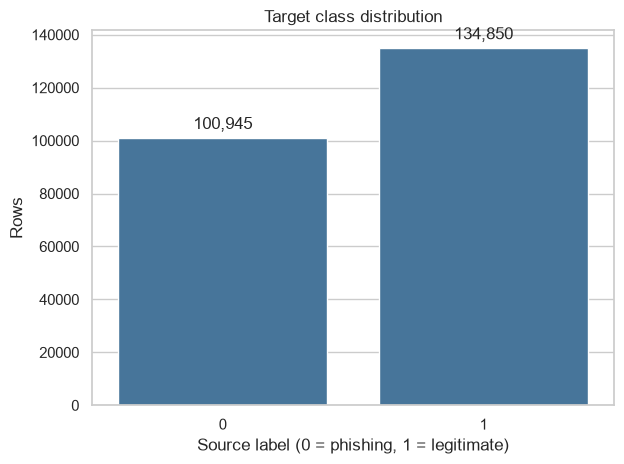

In [3]:
TARGET = "label"
LABEL_MEANING = {0: "Phishing", 1: "Legitimate"}
counts = df[TARGET].value_counts().sort_index()
class_summary = pd.DataFrame({"meaning": [LABEL_MEANING[int(i)] for i in counts.index],
                              "count": counts, "percent": (counts/len(df)*100).round(4)})
display(class_summary)
ax = sns.barplot(x=class_summary.index.astype(str), y=class_summary["count"], color="#3977a8")
ax.set(title="Target class distribution", xlabel="Source label (0 = phishing, 1 = legitimate)", ylabel="Rows")
for bar, n in zip(ax.patches, class_summary["count"]):
    ax.annotate(f"{n:,}", (bar.get_x()+bar.get_width()/2, bar.get_height()), ha="center", va="bottom", xytext=(0,4), textcoords="offset points")
plt.tight_layout(); plt.show()

## 3. Feature inventory and availability

UCI marks `FILENAME` as Other and `label` as target. UCI's per-field descriptions are blank, so inferred categories below use the column names and its dataset-level statement that URL and webpage/source-code properties are present. `YES` means obtainable from the supplied URL string only, without DNS, HTTP, downloads, JavaScript, or rendering. `UNCERTAIN` means the published field definition/formula is insufficient. Domain/TLD fields are identified separately. Lists are methodological candidates, not final feature selection.

In [4]:
URL_ONLY_FEATURES = ["URL", "URLLength", "Domain", "DomainLength", "IsDomainIP", "HasObfuscation",
 "NoOfObfuscatedChar", "ObfuscationRatio", "NoOfLettersInURL", "LetterRatioInURL", "NoOfDegitsInURL",
 "DegitRatioInURL", "NoOfEqualsInURL", "NoOfQMarkInURL", "NoOfAmpersandInURL",
 "NoOfOtherSpecialCharsInURL", "SpacialCharRatioInURL", "IsHTTPS"]
DOMAIN_TLD_FEATURES = ["Domain", "DomainLength", "IsDomainIP", "TLD", "TLDLength", "NoOfSubDomain", "TLDLegitimateProb"]
POST_FETCH_FEATURES = ["LineOfCode", "LargestLineLength", "HasTitle", "Title", "DomainTitleMatchScore", "URLTitleMatchScore",
 "HasFavicon", "Robots", "IsResponsive", "NoOfURLRedirect", "NoOfSelfRedirect", "HasDescription", "NoOfPopup",
 "NoOfiFrame", "HasExternalFormSubmit", "HasSocialNet", "HasSubmitButton", "HasHiddenFields", "HasPasswordField",
 "Bank", "Pay", "Crypto", "HasCopyrightInfo", "NoOfImage", "NoOfCSS", "NoOfJS", "NoOfSelfRef", "NoOfEmptyRef", "NoOfExternalRef"]
METADATA_FIELDS = ["FILENAME"]
availability, category, leakage, requirement = {}, {}, {}, {}
for c in URL_ONLY_FEATURES:
    availability[c] = "YES"; category[c] = "URL string/parser"
    requirement[c] = "Parse supplied URL only; no target contact."
    leakage[c] = "Derived/overlapping URL counts or ratios; raw URL can memorize exact samples."
domain_yes = {"Domain":"Host parsing; no DNS.", "DomainLength":"Length of parsed host.", "IsDomainIP":"Syntactic IP-literal check; do not resolve DNS."}
domain_uncertain = {"TLD":"Public-suffix extraction convention undocumented; observed anomalies need review.",
 "TLDLength":"Depends on exact suffix extraction convention.", "NoOfSubDomain":"Registered-domain/public-suffix rule is undocumented.",
 "TLDLegitimateProb":"Requires reference population/lookup; formula/provenance undocumented and could encode source/labels."}
derived_uncertain = {"URLSimilarityIndex":"Reference set/formula undocumented; could encode target-informed or source-specific information.",
 "CharContinuationRate":"UCI calls it derived but does not provide its formula.",
 "URLCharProb":"Probability reference/formula undocumented; may require corpus statistics."}
for c, why in {**domain_yes, **domain_uncertain}.items():
    category[c] = "Domain/TLD"
    availability[c] = "YES" if c in domain_yes else "UNCERTAIN"
    requirement[c] = why; leakage[c] = "Site identity / correlated parsed fields; " + why
for c, why in derived_uncertain.items():
    category[c] = "Derived URL statistic (definition unclear)"; availability[c] = "UNCERTAIN"
    requirement[c] = why; leakage[c] = why
post_why = {
 "LineOfCode":"Fetched HTML/source.", "LargestLineLength":"Fetched HTML/source.", "HasTitle":"Parse response document.",
 "Title":"Page title/content; high-cardinality site identifier.", "DomainTitleMatchScore":"Page title plus URL/domain.",
 "URLTitleMatchScore":"Page title plus URL; formula undocumented.", "HasFavicon":"Inspect markup or request favicon.",
 "Robots":"Robots.txt/network response or crawl observation; exact encoding unclear.", "IsResponsive":"Page markup/rendering assessment.",
 "NoOfURLRedirect":"Request and observe redirect chain.", "NoOfSelfRedirect":"Requests and compare redirect destinations.",
 "HasDescription":"Parse page metadata.", "NoOfPopup":"Page behavior/script analysis or rendering.", "NoOfiFrame":"Parse HTML.",
 "HasExternalFormSubmit":"Parse forms and destinations.", "HasSocialNet":"Inspect page content/links.", "HasSubmitButton":"Parse page controls/content.",
 "HasHiddenFields":"Parse form/HTML fields.", "HasPasswordField":"Parse form inputs.", "Bank":"Likely page-content category; UCI definition absent.",
 "Pay":"Likely page-content category; UCI definition absent.", "Crypto":"Likely page-content category; UCI definition absent.",
 "HasCopyrightInfo":"Inspect page text/source.", "NoOfImage":"Parse markup/resources.", "NoOfCSS":"Parse markup/resources.",
 "NoOfJS":"Parse markup/resources.", "NoOfSelfRef":"Parse links/resources and compare origins.",
 "NoOfEmptyRef":"Parse links/resources.", "NoOfExternalRef":"Parse links/resources and compare origins."}
for c in POST_FETCH_FEATURES:
    category[c]="Webpage/content/post-fetch"; availability[c]="NO"; requirement[c]=post_why[c]
    leakage[c]=post_why[c] + " Deployment mismatch for URL-only track."
for c in METADATA_FIELDS:
    category[c]="Metadata/identifier"; availability[c]="NO"; requirement[c]="Dataset row identifier; not derivable from submitted URL."
    leakage[c]="UCI says it can be ignored; unique row ID may encode acquisition order/source."
category[TARGET]="Target label"; availability[TARGET]="NO"; requirement[TARGET]="Outcome label, never an inference input."
leakage[TARGET]="Direct target leakage; never a predictor."
assert set(category)==set(df.columns), set(df.columns)-set(category)
inventory = pd.DataFrame({"feature_name":df.columns, "data_type":[str(df[c].dtype) for c in df],
 "unique_values":[int(df[c].nunique(dropna=False)) for c in df], "missing_count":[int(df[c].isna().sum()) for c in df],
 "likely_feature_category":[category[c] for c in df], "URL_only_availability":[availability[c] for c in df],
 "post_fetch_requirement_or_reason":[requirement[c] for c in df], "potential_leakage_concern":[leakage[c] for c in df]})
display(inventory)
print("URL_ONLY_FEATURES:", URL_ONLY_FEATURES)
print("POST_FETCH_FEATURES:", POST_FETCH_FEATURES)
print("UNCERTAIN:", [c for c in df if availability[c]=="UNCERTAIN"])

,feature_name,data_type,unique_values,missing_count,likely_feature_category,URL_only_availability,post_fetch_requirement_or_reason,potential_leakage_concern
0,FILENAME,str,235795,0,Metadata/identifier,NO,Dataset row identifier; not derivable from submitted URL.,UCI says it can be ignored; unique row ID may encode acquisition order/source.
1,URL,str,235370,0,URL string/parser,YES,Parse supplied URL only; no target contact.,Derived/overlapping URL counts or ratios; raw URL can memorize exact samples.
2,URLLength,int64,482,0,URL string/parser,YES,Parse supplied URL only; no target contact.,Derived/overlapping URL counts or ratios; raw URL can memorize exact samples.
3,Domain,str,220086,0,Domain/TLD,YES,Host parsing; no DNS.,Site identity / correlated parsed fields; Host parsing; no DNS.
4,DomainLength,int64,101,0,Domain/TLD,YES,Length of parsed host.,Site identity / correlated parsed fields; Length of parsed host.
5,IsDomainIP,int64,2,0,Domain/TLD,YES,Syntactic IP-literal check; do not resolve DNS.,Site identity / correlated parsed fields; Syntactic IP-literal check; do not resolve DNS.
6,TLD,str,695,0,Domain/TLD,UNCERTAIN,Public-suffix extraction convention undocumented; observed anomalies need review.,Site identity / correlated parsed fields; Public-suffix extraction convention undocumented; observed anoma...
7,URLSimilarityIndex,float64,36360,0,Derived URL statistic (definition unclear),UNCERTAIN,Reference set/formula undocumented; could encode target-informed or source-specific information.,Reference set/formula undocumented; could encode target-informed or source-specific information.
8,CharContinuationRate,float64,898,0,Derived URL statistic (definition unclear),UNCERTAIN,UCI calls it derived but does not provide its formula.,UCI calls it derived but does not provide its formula.
9,TLDLegitimateProb,float64,465,0,Domain/TLD,UNCERTAIN,Requires reference population/lookup; formula/provenance undocumented and could encode source/labels.,Site identity / correlated parsed fields; Requires reference population/lookup; formula/provenance undocum...


URL_ONLY_FEATURES: ['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS']
POST_FETCH_FEATURES: ['LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']
UNCERTAIN: ['TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain']


## 4. Numerical summaries, skew, and IQR outlier screen

Statistics use all rows. IQR flags (`< Q1−1.5×IQR` or `> Q3+1.5×IQR`) are descriptive only, especially limited for binary/count fields; no records are removed.

In [5]:
numeric_features = [c for c in df.select_dtypes(include=np.number).columns if c != TARGET]
numeric_desc = df[numeric_features].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T
numeric_desc["skew"] = df[numeric_features].skew(numeric_only=True)
display(numeric_desc)
class_stats = df.groupby(TARGET)[numeric_features].agg(["mean","median","std"])
display(class_stats.T)
q1, q3 = df[numeric_features].quantile(.25), df[numeric_features].quantile(.75)
iqr = q3-q1
flag = df[numeric_features].lt(q1-1.5*iqr) | df[numeric_features].gt(q3+1.5*iqr)
outlier_summary = pd.DataFrame({"iqr_flag_count":flag.sum().astype(int), "iqr_flag_pct":(flag.mean()*100).round(3),
                                "skew":df[numeric_features].skew().round(3)}).sort_values("iqr_flag_pct",ascending=False)
display(outlier_summary.head(20))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew
URLLength,235795.0,34.573095,41.314153,13.000000,17.000000,19.000000,23.000000,27.000000,34.000000,73.000000,144.000000,6.097000e+03,53.321737
DomainLength,235795.0,21.470396,9.150793,4.000000,8.000000,12.000000,16.000000,20.000000,24.000000,38.000000,57.000000,1.100000e+02,2.513397
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000e+00,19.146593
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,8.284552,18.974135,57.024793,100.000000,100.000000,100.000000,100.000000,1.000000e+02,-0.989903
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.250000,0.400000,0.680000,1.000000,1.000000,1.000000,1.000000,1.000000e+00,-1.128591
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.000037,0.000228,0.005977,0.079963,0.522907,0.522907,0.522907,5.229071e-01,0.073090
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.022839,0.034904,0.050747,0.057970,0.062875,0.069195,0.073798,9.082366e-02,-1.064291
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,4.000000,1.300000e+01,1.663518
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,2.000000,3.000000,1.000000e+01,1.809400
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000e+00,21.981435


label                           0           1
URLLength       mean    45.720293   26.228610
                median  34.000000   26.000000
                std     61.145523    4.815612
DomainLength    mean    24.465144   19.228610
                median  22.000000   19.000000
...                           ...         ...
NoOfEmptyRef    median   0.000000    1.000000
                std      1.781620   23.136610
NoOfExternalRef mean     1.128119   85.294601
                median   0.000000   46.000000
                std      3.204587  205.669475

[150 rows x 2 columns]

,iqr_flag_count,iqr_flag_pct,skew
NoOfSubDomain,57389,24.339,1.809
Pay,55885,23.701,1.237
NoOfDegitsInURL,51461,21.824,94.878
DegitRatioInURL,51461,21.824,3.245
IsHTTPS,51256,21.738,-1.370
NoOfEmptyRef,38885,16.491,106.826
NoOfiFrame,34441,14.606,97.677
HasTitle,32714,13.874,-2.090
NoOfURLRedirect,31464,13.344,2.156
Bank,29967,12.709,2.239


## 5. Class-conditional discrimination and selected distributions

Full data is used for rank-based univariate AUC. It is `P(phishing value > legitimate value)`; 0.5 indicates no rank separation and direction is retained. It is not model performance or final feature importance. Plots use a fixed-seed sample of at most 8,000 per class; this stratified sample is for readability only. Selected nonnegative count axes use log1p for display only.

,feature,phishing_higher_value_auc,abs_distance_from_0_5,cliffs_delta,phishing_median,legitimate_median,phish_q25,phish_q75,legit_q25,legit_q75
3,URLSimilarityIndex,0.003893,0.496107,-0.992214,51.419332,100.000000,32.120613,67.251462,100.000000,100.000000
22,LineOfCode,0.009745,0.490255,-0.980509,12.000000,1105.000000,2.000000,90.000000,613.000000,2088.000000
49,NoOfExternalRef,0.011979,0.488021,-0.976043,0.000000,46.000000,0.000000,1.000000,17.000000,106.000000
44,NoOfImage,0.020365,0.479635,-0.959269,0.000000,25.000000,0.000000,0.000000,13.000000,47.000000
47,NoOfSelfRef,0.027544,0.472456,-0.944913,0.000000,76.000000,0.000000,0.000000,35.000000,140.000000
46,NoOfJS,0.029177,0.470823,-0.941646,0.000000,14.000000,0.000000,0.000000,8.000000,23.000000
45,NoOfCSS,0.042404,0.457596,-0.915193,0.000000,6.000000,0.000000,0.000000,3.000000,13.000000
36,HasSocialNet,0.105253,0.394747,-0.789495,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000
43,HasCopyrightInfo,0.124550,0.375450,-0.750901,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000
32,HasDescription,0.153765,0.346235,-0.692471,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000


Plot sample: 16,000 rows, up to 8,000/class, random_state=2026


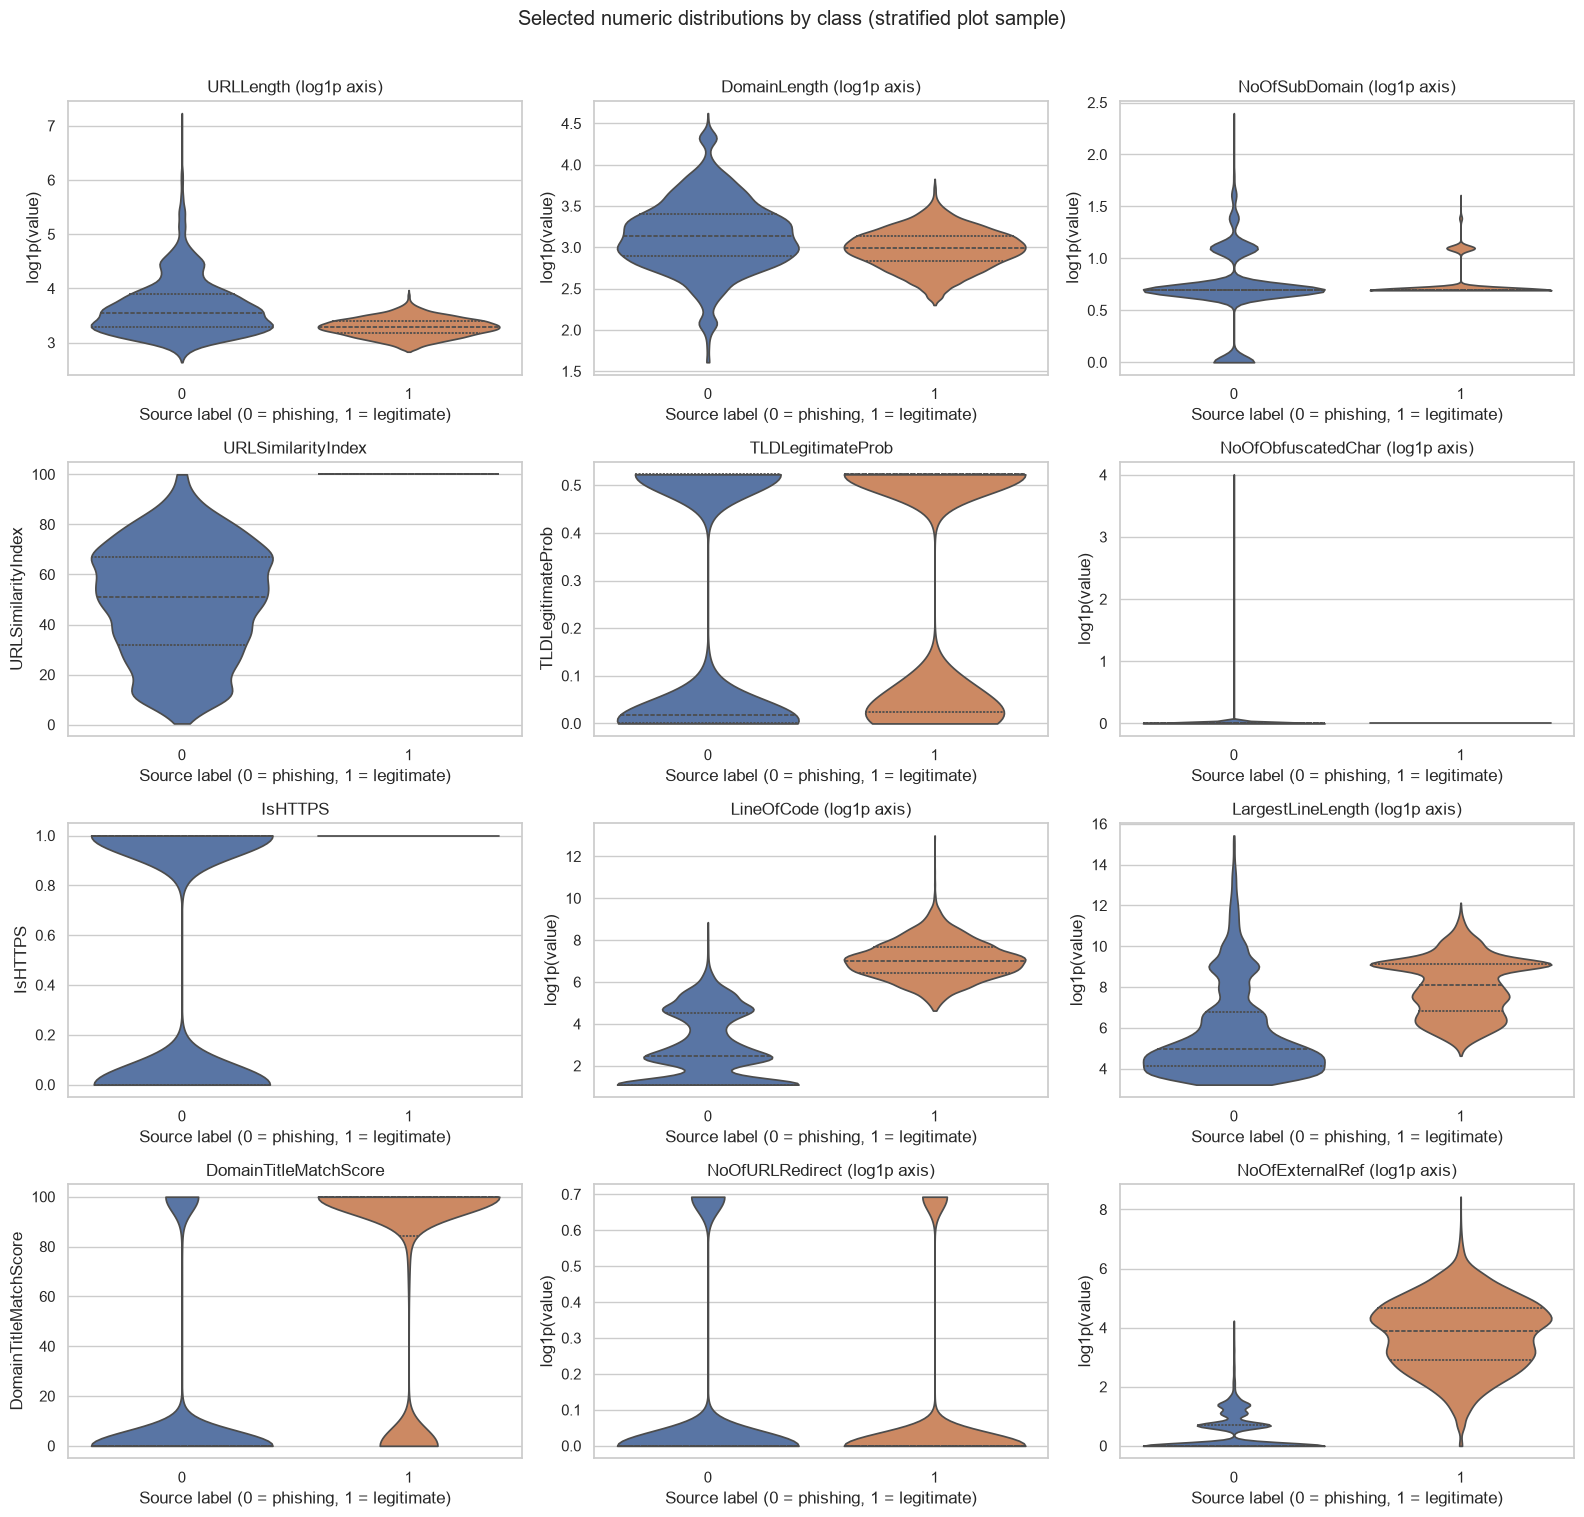

In [6]:
phish, legit = df[df[TARGET]==0], df[df[TARGET]==1]
auc_rows=[]
for c in numeric_features:
    if df[c].nunique(dropna=True)>1:
        u=mannwhitneyu(phish[c].dropna(),legit[c].dropna(),alternative="two-sided",method="asymptotic").statistic
        a=float(u/(phish[c].notna().sum()*legit[c].notna().sum()))
        auc_rows.append({"feature":c,"phishing_higher_value_auc":a,"abs_distance_from_0_5":abs(a-.5),"cliffs_delta":2*a-1,
         "phishing_median":phish[c].median(),"legitimate_median":legit[c].median(),
         "phish_q25":phish[c].quantile(.25),"phish_q75":phish[c].quantile(.75),
         "legit_q25":legit[c].quantile(.25),"legit_q75":legit[c].quantile(.75)})
univariate=pd.DataFrame(auc_rows).sort_values("abs_distance_from_0_5",ascending=False)
display(univariate.head(25))
plot_df=pd.concat([g.sample(n=min(8000,len(g)),random_state=2026) for _,g in df.groupby(TARGET,sort=True)],ignore_index=True)
print(f"Plot sample: {len(plot_df):,} rows, up to 8,000/class, random_state=2026")
preferred=["URLLength","DomainLength","NoOfSubDomain","URLSimilarityIndex","TLDLegitimateProb","NoOfObfuscatedChar",
 "IsHTTPS","LineOfCode","LargestLineLength","DomainTitleMatchScore","NoOfURLRedirect","NoOfExternalRef"]
selected=[c for c in preferred if c in numeric_features]
fig,axes=plt.subplots(4,3,figsize=(16,15))
log_fields={"URLLength","DomainLength","NoOfSubDomain","NoOfObfuscatedChar","LineOfCode","LargestLineLength","NoOfURLRedirect","NoOfExternalRef"}
for ax,c in zip(axes.flat,selected):
    z=plot_df[[TARGET,c]].copy(); use_log=c in log_fields and z[c].min()>=0
    z["display_value"]=np.log1p(z[c]) if use_log else z[c]
    sns.violinplot(data=z,x=TARGET,y="display_value",hue=TARGET,legend=False,inner="quartile",cut=0,density_norm="width",ax=ax)
    ax.set(title=c+(" (log1p axis)" if use_log else ""),xlabel="Source label (0 = phishing, 1 = legitimate)",ylabel="log1p(value)" if use_log else c)
for ax in axes.flat[len(selected):]: ax.remove()
fig.suptitle("Selected numeric distributions by class (stratified plot sample)",y=1.01)
plt.tight_layout(); plt.show()

## 6. Categorical columns and cardinality

Analyze Domain, TLD, Title, and FILENAME without one-hot encoding. Singleton rates and repeated-group label mixing help expose memorization risks; top-category target composition is descriptive and does not establish generalization.

,unique_values,unique_ratio,singleton_rows_pct,max_category_rows,repeated_categories,repeated_groups_with_both_labels,suitability
feature,,,,,,,
Domain,220086,0.933379,90.994296,1197,5526,54,High-cardinality site identifier; investigate grouped evaluation.
TLD,695,0.002947,0.064463,112554,543,334,Moderate-cardinality; suffix convention and observed parsing anomalies need review.
Title,197874,0.839178,82.075956,32719,4343,222,High-cardinality page content; post-fetch and site/template memorization risk.
FILENAME,235795,1.000000,100.000000,1,0,0,Unique row identifier; UCI says it can be ignored; do not use as predictor.


Top categories: Domain


,count
Domain,
ipfs.io,1197
docs.google.com,526
mail.deliverylifesupport.com,370
cloudflare-ipfs.com,359
storageapi.fleek.co,318
gateway.pinata.cloud,275
gateway.ipfs.io,249
ipfs.litnet.work,223
cf-ipfs.com,190


Top categories: TLD


,count
TLD,
com,112554
org,18793
net,7097
app,6508
uk,6395
co,5422
io,4201
de,3996
ru,3875


Top categories: Title


,count
Title,
0,32719
#NAME?,21
65gfgfgfgfg4g4gblogspot?m=1,12
gov,11
info-update-sucreeblogspot,10
u,9
security-page-community-standardsblogspot,9
a,7
myip,7


Top categories: FILENAME


,count
FILENAME,
521848.txt,1
31372.txt,1
597387.txt,1
554095.txt,1
151578.txt,1
23107.txt,1
23034.txt,1
696732.txt,1
739255.txt,1


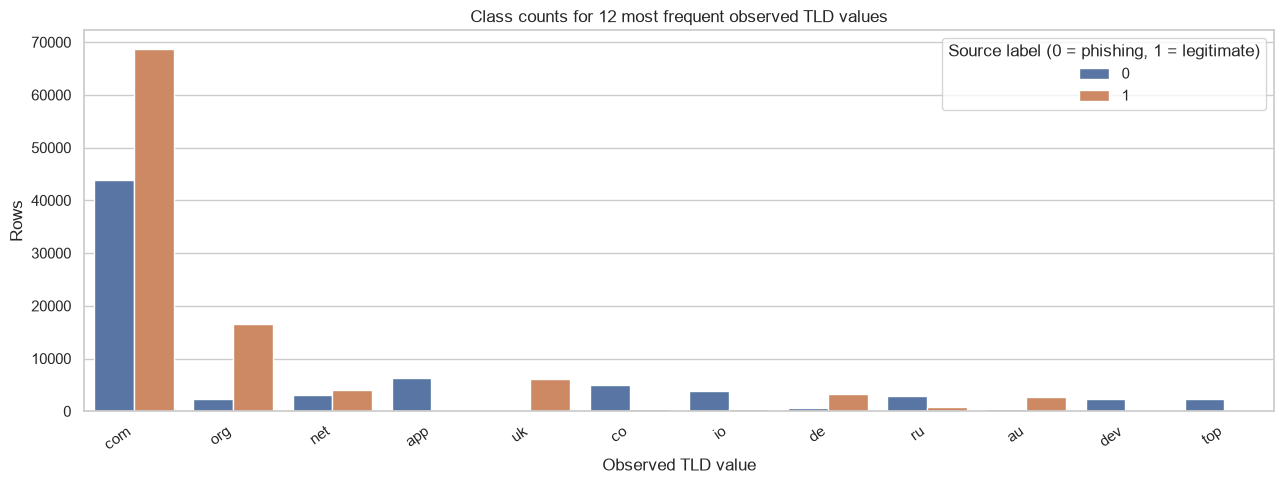

In [7]:
focus=[c for c in ["Domain","TLD","Title","FILENAME"] if c in df]
cat_rows=[]; top_cats={}
notes={"Domain":"High-cardinality site identifier; investigate grouped evaluation.",
 "TLD":"Moderate-cardinality; suffix convention and observed parsing anomalies need review.",
 "Title":"High-cardinality page content; post-fetch and site/template memorization risk.",
 "FILENAME":"Unique row identifier; UCI says it can be ignored; do not use as predictor."}
for c in focus:
    vc=df[c].value_counts(dropna=False); label_n=df.groupby(c,dropna=False)[TARGET].nunique()
    cat_rows.append({"feature":c,"unique_values":df[c].nunique(dropna=False),"unique_ratio":df[c].nunique(dropna=False)/len(df),
      "singleton_rows_pct":(vc==1).sum()/len(df)*100,"max_category_rows":vc.max(),"repeated_categories":(vc>1).sum(),
      "repeated_groups_with_both_labels":(label_n>1).sum(),"suitability":notes[c]})
    top_cats[c]=vc.head(12)
display(pd.DataFrame(cat_rows).set_index("feature"))
for c in focus:
    print("Top categories:",c); display(top_cats[c].rename("count").to_frame())
if "TLD" in df:
    order=df.TLD.value_counts().head(12).index.tolist()
    counts_tld=df[df.TLD.isin(order)].groupby(["TLD",TARGET]).size().rename("rows").reset_index()
    plt.figure(figsize=(13,5)); sns.barplot(data=counts_tld,x="TLD",y="rows",hue=TARGET,order=order)
    plt.title("Class counts for 12 most frequent observed TLD values"); plt.xlabel("Observed TLD value"); plt.ylabel("Rows")
    plt.xticks(rotation=35,ha="right"); plt.legend(title="Source label (0 = phishing, 1 = legitimate)")
    plt.tight_layout(); plt.show()

## 7. Correlation and redundancy

Spearman rank correlation is suitable for this mixture of skewed counts, bounded ratios, and binary fields. The heatmap is a curated subset; a scan of the full numerical set identifies strong pairs. The label is excluded. Correlation flags possible redundancy/multicollinearity, not a removal instruction.

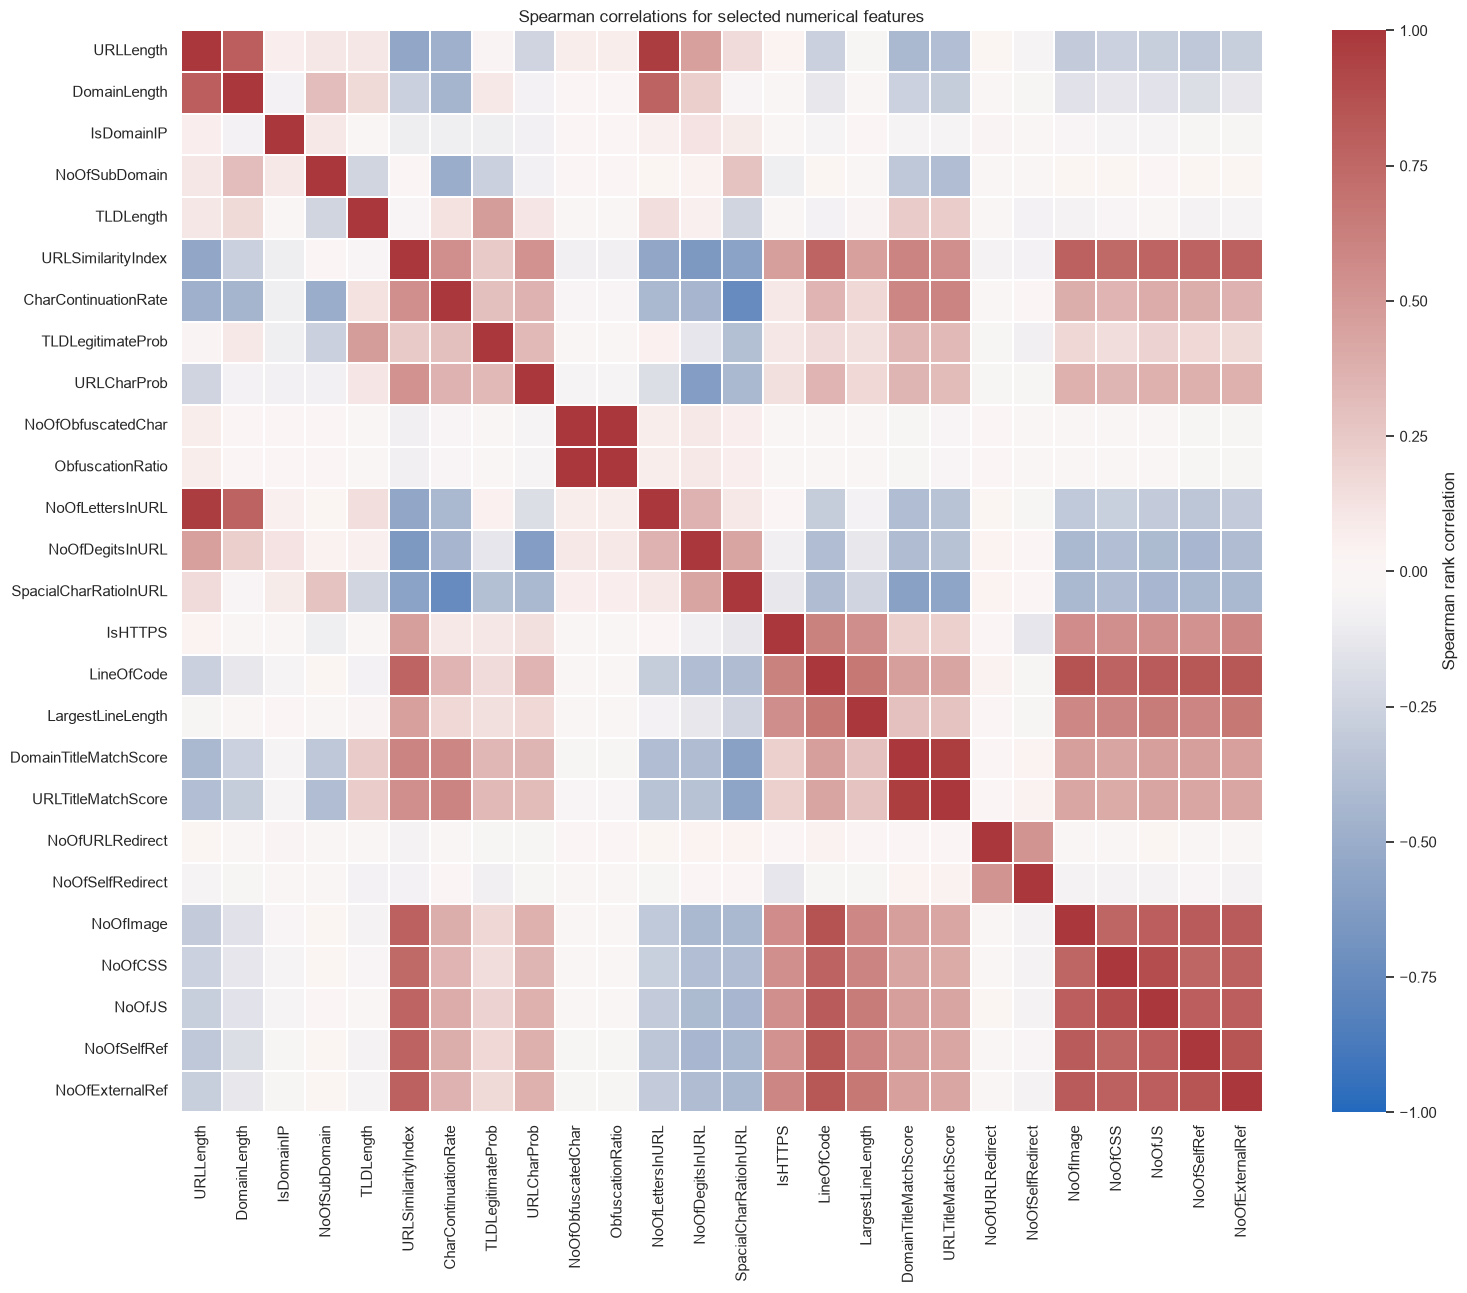

,feature_1,feature_2,spearman_rho,abs_rho
445,NoOfObfuscatedChar,ObfuscationRatio,1.000000,1.000000
405,HasObfuscation,NoOfObfuscatedChar,0.999999,0.999999
406,HasObfuscation,ObfuscationRatio,0.999999,0.999999
595,NoOfDegitsInURL,DegitRatioInURL,0.996737,0.996737
11,URLLength,NoOfLettersInURL,0.972084,0.972084
925,DomainTitleMatchScore,URLTitleMatchScore,0.964232,0.964232
522,NoOfLettersInURL,LetterRatioInURL,0.930667,0.930667
664,NoOfEqualsInURL,NoOfQMarkInURL,0.909746,0.909746
1215,NoOfCSS,NoOfJS,0.883880,0.883880
868,LineOfCode,NoOfImage,0.866877,0.866877


Pairs with |rho| >= .90: 8


In [8]:
heat_features=[c for c in ["URLLength","DomainLength","IsDomainIP","NoOfSubDomain","TLDLength","URLSimilarityIndex",
 "CharContinuationRate","TLDLegitimateProb","URLCharProb","NoOfObfuscatedChar","ObfuscationRatio","NoOfLettersInURL",
 "NoOfDegitsInURL","SpacialCharRatioInURL","IsHTTPS","LineOfCode","LargestLineLength","DomainTitleMatchScore",
 "URLTitleMatchScore","NoOfURLRedirect","NoOfSelfRedirect","NoOfImage","NoOfCSS","NoOfJS","NoOfSelfRef","NoOfExternalRef"] if c in numeric_features]
plt.figure(figsize=(16,13)); sns.heatmap(df[heat_features].corr(method="spearman"),cmap="vlag",center=0,vmin=-1,vmax=1,square=True,
 linewidths=.25,cbar_kws={"label":"Spearman rank correlation"})
plt.title("Spearman correlations for selected numerical features"); plt.tight_layout(); plt.show()
full_corr=df[numeric_features].corr(method="spearman")
pairs=[(a,b,float(full_corr.loc[a,b])) for i,a in enumerate(numeric_features) for b in numeric_features[i+1:] if pd.notna(full_corr.loc[a,b])]
pair_table=pd.DataFrame(pairs,columns=["feature_1","feature_2","spearman_rho"]); pair_table["abs_rho"]=pair_table.spearman_rho.abs()
display(pair_table.sort_values("abs_rho",ascending=False).head(30))
print("Pairs with |rho| >= .90:",int((pair_table.abs_rho>=.90).sum()))

## 8. Leakage and deployment risks

No columns are dropped. Provisional actions are experiment controls, not final feature selection.

In [9]:
risks=[
 ("FILENAME","Unique row ID / source-order leakage","235,795 unique; UCI says it can be ignored; generation provenance is unclear.","Exclude from predictors; inspect provenance."),
 ("URL","Exact indicator memorization / duplicate partition leakage","235,370 unique and 425 repeated occurrences.","Keep as submitted input/audit key; future validation should group repeats."),
 ("Domain","Site identity/group leakage","220,086 distinct hosts can be memorized.","Investigate domain-grouped validation; report tracks separately."),
 ("Title","Page content, site identity, deployment mismatch","197,874 unique; requires fetched page.","Benchmark-only/investigate; exclude URL-only track."),
 ("Repeated URLs","Same indicator can cross partitions","425 duplicate URL occurrences.","Preserve raw data; group duplicates during future split design and inspect label conflicts."),
 ("Similarity/probability/derived fields","Possible target/source-informed statistics","UCI notes some fields are derived but publishes no formulas/reference data.","Investigate provenance before use; keep URL-only status uncertain."),
 ("TLDLegitimateProb","Potential target or source prior","Requires a reference population and may encode dataset composition.","Investigate; require independently defined, versioned lookup."),
 ("URL counts/ratios","Mathematical redundancy","Lengths, counts, ratios, and obfuscation metrics reuse the same string.","Benchmark candidates; quantify redundancy later."),
 ("Post-fetch features","Deployment mismatch and collection artifacts","Require HTML/page/network behavior; collection details are underspecified.","Full-track benchmark only; no URL-only performance claim."),
 ("Dataset/source ordering","Temporal or acquisition shortcut","UCI variable metadata does not fully describe sampling/order.","Investigate provenance and future time/group-aware evaluation.")]
leakage_table=pd.DataFrame(risks,columns=["Feature","Concern","Reason","Action for future experiments"])
display(leakage_table)

,Feature,Concern,Reason,Action for future experiments
0,FILENAME,Unique row ID / source-order leakage,"235,795 unique; UCI says it can be ignored; generation provenance is unclear.",Exclude from predictors; inspect provenance.
1,URL,Exact indicator memorization / duplicate partition leakage,"235,370 unique and 425 repeated occurrences.",Keep as submitted input/audit key; future validation should group repeats.
2,Domain,Site identity/group leakage,"220,086 distinct hosts can be memorized.",Investigate domain-grouped validation; report tracks separately.
3,Title,"Page content, site identity, deployment mismatch","197,874 unique; requires fetched page.",Benchmark-only/investigate; exclude URL-only track.
4,Repeated URLs,Same indicator can cross partitions,425 duplicate URL occurrences.,Preserve raw data; group duplicates during future split design and inspect label conflicts.
5,Similarity/probability/derived fields,Possible target/source-informed statistics,UCI notes some fields are derived but publishes no formulas/reference data.,Investigate provenance before use; keep URL-only status uncertain.
6,TLDLegitimateProb,Potential target or source prior,Requires a reference population and may encode dataset composition.,"Investigate; require independently defined, versioned lookup."
7,URL counts/ratios,Mathematical redundancy,"Lengths, counts, ratios, and obfuscation metrics reuse the same string.",Benchmark candidates; quantify redundancy later.
8,Post-fetch features,Deployment mismatch and collection artifacts,Require HTML/page/network behavior; collection details are underspecified.,Full-track benchmark only; no URL-only performance claim.
9,Dataset/source ordering,Temporal or acquisition shortcut,UCI variable metadata does not fully describe sampling/order.,Investigate provenance and future time/group-aware evaluation.


## 9. Interpretation and limitations

This notebook establishes descriptive evidence, not model performance. UCI's field descriptions are blank, particularly limiting formula/provenance assessment for probability and similarity measures. A `YES` assessment permits parsing the supplied URL only; it does not allow checking DNS resolution or whether HTTPS actually negotiates TLS. TLD conventions and corpus-derived values remain uncertain where their definitions are unpublished. The analysis does not alter raw data, deduplicate, select features, create processed data, split records, or train a model.